<a href="https://colab.research.google.com/github/Shersss155/Data-Science-/blob/main/P170173_Week_7_Data_Manipulation_Pandas_REVISED_261122.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Week 7: Pandas Fundamentals, Indexing, and Data Manipulation**

Most examples follow **Python Data Science Handbook** by Jake VanderPlas (Chapter 3, *Data Manipulation with Pandas*). It is free to read online: https://jakevdp.github.io/PythonDataScienceHandbook/

> ⚠️ **Version note:** these notes are written for **pandas 3.x** (released January 2026). Older tutorials may show `dtype: object` for text columns, where pandas 3 now shows `dtype: str`. Run the first code cell to check which version you have.

## **Learning Outcomes**

By the end of this lecture, students should be able to:

1. Explain the difference between a Pandas **Series** and a **DataFrame**.
2. Use **implicit** (position) and **explicit** (label) indexing to select data.
3. Apply `loc` and `iloc` correctly.
4. Filter data using **Boolean masks**.
5. Detect and handle missing values using `isna()`, `dropna()` and `fillna()`.
6. Reshape data using `stack()` and `unstack()`.
7. Interpret and manipulate data with **MultiIndex** structures.
8. Perform a basic data-manipulation workflow on a real dataset: load, inspect, clean, create new columns, filter, **sort** and **summarise**.

| Part | Topic | Outcome |
|---|---|---|
| 0 | Setup | – |
| 1 | The Series | 1 |
| 2 | The DataFrame | 1 |
| 3 | Selecting data: implicit vs explicit, `loc` / `iloc` | 2, 3 |
| 4 | Filtering with masks | 4 |
| 5 | Operations and index alignment | 2 |
| 6 | Missing values | 5 |
| 7 | MultiIndex and reshaping | 6, 7 |
| 8 | Mini case study (real data) | 8 |

---
## **Part 0: Setup**

We import **NumPy** (fast arrays and maths) and **pandas** (tables). We also create **one** random-number generator with a fixed *seed*, so everyone gets the same "random" numbers every time the notebook runs.

In [ ]:
import numpy as np
import pandas as pd

print("pandas version:", pd.__version__)
print("numpy version :", np.__version__)

# One random-number generator for the whole notebook.
# A fixed seed (42) makes the "random" numbers reproducible.
rng = np.random.default_rng(42)

pandas version: 2.2.3
numpy version : 2.4.6


> 💡 **In plain words:** a *seed* is like the starting page of a book of random numbers. Same seed → same page → same numbers. We create `rng` **once** and do not reset it. That's why you should run the notebook **from top to bottom** (*Runtime → Run all* in Colab).

---
## **Part 1: The Pandas Series: a One-Dimensional Labelled Array**

A **Series** holds two things:
- a sequence of **values**, and
- a sequence of **labels** (the **index**), one per value.

> 💡 **In plain words:** a Series is like **one column in Excel**, with a name tag on every row.

In [ ]:
# A Series wraps a sequence of values AND a sequence of index labels
data = pd.Series([0.25, 0.5, 0.75, 1.0])
data

,0
0,0.25
1,0.50
2,0.75
3,1.00


In [1]:
print(data.values)   # the values (a NumPy array)
print(data.index)    # the labels: here pandas created 0, 1, 2, 3 automatically

NameError: name 'data' is not defined

In [ ]:
# Select the first value BY POSITION
data.iloc[0]

np.float64(0.25)

> ⚠️ **Why `.iloc[0]` and not `data[0]`?** Here `data[0]` would also work, but only because the labels happen to be 0, 1, 2, 3. In pandas 3, `s[0]` on a Series with labels like `'a', 'b'` raises a `KeyError`. Good habit: use **`.iloc`** for position and **`.loc`** for labels (Part 3).

### **Creating a Series from a Dictionary**
- The **dictionary keys** become the **index labels**.
- The **dictionary values** become the **data values**.

In [ ]:
pop_dict = {'California': 38332521,
            'Texas': 26448193,
            'New York': 19651127,
            'Florida': 19552860,
            'Illinois': 12882135}

population = pd.Series(pop_dict)
population

,0
California,38332521
Texas,26448193
New York,19651127
Florida,19552860
Illinois,12882135


In [ ]:
# Select one value by its label
population['California']

np.int64(38332521)

In [ ]:
# Slice by label: NOTE the end label 'New York' is INCLUDED (explained in Part 3)
population['California':'New York']

,0
California,38332521
Texas,26448193
New York,19651127


### **A Series Behaves Like a Dictionary**
Because every value has a label, many dictionary habits work on a Series.

In [ ]:
data = pd.Series([0.25, 0.5, 0.75, 1.0],
                 index=['a', 'b', 'c', 'd'])
data

,0
a,0.25
b,0.50
c,0.75
d,1.00


In [ ]:
# Is 'b' one of the labels?
'b' in data

True

In [ ]:
# keys() returns the index labels
data.keys()

Index(['a', 'b', 'c', 'd'], dtype='object')

In [ ]:
# items() gives (label, value) pairs.
# Each pair is a TUPLE: an ordered collection that cannot be changed.
list(data.items())

[('a', 0.25), ('b', 0.5), ('c', 0.75), ('d', 1.0)]

In [ ]:
# Add a new entry by assigning to a new label
data['e'] = 1.25
data

,0
a,0.25
b,0.50
c,0.75
d,1.00
e,1.25


---
## **Part 2: The Pandas DataFrame: a Two-Dimensional Labelled Table**

A DataFrame has two labelled axes:
- **rows**, identified by the **index**
- **columns**, identified by **column names**

> 💡 **In plain words:** a DataFrame is like an **Excel sheet**: several Series (columns) that share the same row labels.

### **Creating a DataFrame from Several Series**

In [ ]:
# Area of each state in square kilometres (km²)
area_dict = {'California': 423967, 'Texas': 695662, 'New York': 141297,
             'Florida': 170312, 'Illinois': 149995}
area = pd.Series(area_dict)

# A dictionary of Series → each key becomes a column name
states = pd.DataFrame({'population': population,
                       'area_km2': area})
states

,population,area_km2
California,38332521,423967
Texas,26448193,695662
New York,19651127,141297
Florida,19552860,170312
Illinois,12882135,149995


### **Single Brackets vs Double Brackets**

In [ ]:
# Single brackets → a Series
print(type(states['population']))
states['population']

<class 'pandas.core.series.Series'>


,population
California,38332521
Texas,26448193
New York,19651127
Florida,19552860
Illinois,12882135


In [ ]:
# Double brackets → a DataFrame (a list of column names, here a list of one)
print(type(states[['population']]))
states[['population']]

<class 'pandas.core.frame.DataFrame'>


,population
California,38332521
Texas,26448193
New York,19651127
Florida,19552860
Illinois,12882135


> 💡 **In plain words:** **double brackets keep the table shape.** `[ ]` pulls out one column as a Series. `[[ ]]` gives a smaller table.

### **Turning a Single Series into a DataFrame**

In [ ]:
# Without a column name, pandas names the column 0
pd.DataFrame(area)

,0
California,423967
Texas,695662
New York,141297
Florida,170312
Illinois,149995


In [ ]:
# Better: give the column a meaningful name with to_frame()
area.to_frame(name='area_km2')

,area_km2
California,423967
Texas,695662
New York,141297
Florida,170312
Illinois,149995


### **Creating a DataFrame from a List of Dictionaries**

In [ ]:
# A list comprehension that builds a list of 3 dictionaries (one per row).
# i takes the values 0, 1, 2
rows = [{'a': 1, 'b': 2 * i} for i in range(3)]
rows

[{'a': 1, 'b': 0}, {'a': 1, 'b': 2}, {'a': 1, 'b': 4}]

In [ ]:
# Each dictionary becomes one row; keys become column names
pd.DataFrame(rows)

,a,b
0,1,0
1,1,2
2,1,4


### **Creating a DataFrame from a Two-Dimensional NumPy Array**

Two random-number functions are used in this lecture:

| Function | What it gives | In plain words |
|---|---|---|
| `rng.random((r, c))` | numbers from a **uniform** distribution in `[0, 1)` | every value between 0 and 1 is equally likely, like a fair spinner |
| `rng.standard_normal(n)` | numbers from a **standard normal** distribution (mean 0, standard deviation 1) | most values sit near 0 and extreme values are rare, like people's heights around the average |
| `rng.integers(low, high, size)` | whole numbers from `low` up to, but **not including**, `high` | like rolling a die |

In [ ]:
# VanderPlas example: a 3 x 2 table of uniform random numbers
pd.DataFrame(rng.random((3, 2)),
             columns=['foo', 'bar'],
             index=['a', 'b', 'c'])

,foo,bar
a,0.773956,0.438878
b,0.858598,0.697368
c,0.094177,0.975622


In [ ]:
# A more meaningful example: quiz scores (0 to 1) for three students
scores = pd.DataFrame(rng.random((3, 3)),
                      columns=['quiz1', 'quiz2', 'quiz3'],
                      index=['Ali', 'Abu', 'Siti'])
scores

,quiz1,quiz2,quiz3
Ali,0.761140,0.786064,0.128114
Abu,0.450386,0.370798,0.926765
Siti,0.643865,0.822762,0.443414


In [ ]:
# Create new columns from existing ones
scores['bonus'] = rng.standard_normal(3)          # mean 0, can be negative
scores['ratio'] = scores['quiz1'] / scores['quiz2']
scores

,quiz1,quiz2,quiz3,bonus,ratio
Ali,0.761140,0.786064,0.128114,-0.859292,0.968292
Abu,0.450386,0.370798,0.926765,0.368751,1.214640
Siti,0.643865,0.822762,0.443414,-0.958883,0.782566


In [ ]:
# Average of the 'ratio' column
scores['ratio'].mean()

np.float64(0.9884990857575043)

---
## **Part 3: Selecting Data: Implicit vs Explicit Indexing**

Every value in pandas can be reached in **two** ways:

| Concept | Meaning | Example | Pandas tool |
|---|---|---|---|
| **Implicit** index | the **position**, decided automatically by order (0, 1, 2, …) | 3rd row → position `2` | `iloc` |
| **Explicit** index | a **label** you assign on purpose | `'California'`, `'a'`, `2010` | `loc` |

> 💡 **In plain words:** `iloc` = **call by seat number** ("whoever sits in seat 2"). `loc` = **call by name tag** ("the person named California"). One person has both a seat number and a name.

### **Recap: Slicing a Python List (Positions)**
**Rule:** `[start:end]`. The **start is included**, the **end is excluded**.

In [ ]:
my_list = [0, 1, 2, 3, 4, 5]

print(my_list[1:4])   # [1, 2, 3]  start at seat 1, stop BEFORE seat 4
print(my_list[:3])    # [0, 1, 2]  empty start = from the beginning
print(my_list[2:])    # [2, 3, 4, 5]  empty end = to the end
print(my_list[:])     # whole list

[1, 2, 3]
[0, 1, 2]
[2, 3, 4, 5]
[0, 1, 2, 3, 4, 5]


### **Slicing by Label: the End IS Included**
With labels, the end label is **included**. Labels have no natural "one before the end", so pandas includes it.

In [ ]:
sales = pd.Series([25, 5, 75, 1],
                  index=['Mon', 'Tue', 'Wed', 'Thu'])

sales['Tue':'Thu']   # Tue, Wed AND Thu

,0
Tue,5
Wed,75
Thu,1


### **Indexers: `loc` and `iloc`**
The difference matters most when the **labels are themselves integers**. This VanderPlas example shows why.

In [ ]:
# Labels are 1, 3, 5; positions are 0, 1, 2
s = pd.Series(['a', 'b', 'c'], index=[1, 3, 5])
s

,0
1,a
3,b
5,c


#### `loc`: always uses the **explicit label**

In [ ]:
s.loc[1]      # the value whose LABEL is 1 → 'a'

'a'

In [ ]:
s.loc[1:3]    # labels 1 up to AND including 3 → 'a', 'b'

,0
1,a
3,b


#### `iloc`: always uses the **implicit position** (Python-style)

In [ ]:
s.iloc[1]     # the value in POSITION 1 → 'b'

'b'

In [ ]:
s.iloc[1:3]   # positions 1 and 2 (3 is excluded) → 'b', 'c'

,0
3,b
5,c


### 🔑 **Key Takeaway: Same Numbers, Different Answers**

| Code | Reads as | Result |
|---|---|---|
| `s.loc[1:3]` | labels 1 → 3, **end included** | `a, b` |
| `s.iloc[1:3]` | positions 1 → 2, **end excluded** | `b, c` |

Plain `s[1]` is ambiguous (label or position?). **Always say which one you mean with `loc` or `iloc`.**

### **`loc` and `iloc` on a DataFrame: `[rows, columns]`**

In [ ]:
# Add a new column: people per km²
states['density'] = states['population'] / states['area_km2']
states

,population,area_km2,density
California,38332521,423967,90.413926
Texas,26448193,695662,38.018740
New York,19651127,141297,139.076746
Florida,19552860,170312,114.806121
Illinois,12882135,149995,85.883763


In [ ]:
# Transpose: swap rows and columns
states.T

,California,Texas,New York,Florida,Illinois
population,3.833252e+07,2.644819e+07,1.965113e+07,1.955286e+07,1.288214e+07
area_km2,4.239670e+05,6.956620e+05,1.412970e+05,1.703120e+05,1.499950e+05
density,9.041393e+01,3.801874e+01,1.390767e+02,1.148061e+02,8.588376e+01


Notice the transposed table shows every number as a float in scientific notation. Each column in pandas holds **one data type**, so mixing integers (population) and decimals (density) in one column turns them all into floats.

In [ ]:
# iloc: first 3 rows, first 2 columns (by position; ends excluded)
states.iloc[:3, :2]

,population,area_km2
California,38332521,423967
Texas,26448193,695662
New York,19651127,141297


In [ ]:
# loc: rows up to 'Florida', columns up to 'area_km2' (by label; ends INCLUDED)
states.loc[:'Florida', :'area_km2']

,population,area_km2
California,38332521,423967
Texas,26448193,695662
New York,19651127,141297
Florida,19552860,170312


In [ ]:
# loc with a condition: rows where density > 100, and only two columns
states.loc[states['density'] > 100, ['population', 'density']]

,population,density
New York,19651127,139.076746
Florida,19552860,114.806121


> ✅ Write `states['density']` rather than `states.density`. The dot form breaks for column names with spaces, or names that clash with built-in methods (e.g. a column called `count`).

### **Editing a Value with `loc`**

In [ ]:
states.loc['Illinois', 'area_km2'] = 149996
states

,population,area_km2,density
California,38332521,423967,90.413926
Texas,26448193,695662,38.018740
New York,19651127,141297,139.076746
Florida,19552860,170312,114.806121
Illinois,12882135,149996,85.883763


> ⚠️ **Always edit with `df.loc[row, column] = value`.** Since pandas 3.0 (*Copy-on-Write*), any selection behaves like a **copy**. So "chained" code such as `states['area_km2']['Illinois'] = 149996` changes the copy, **not** your table.

### **Optional: The Pandas Index Object**
The index is itself an object. It behaves like an **immutable array** and like an **ordered set**.

In [ ]:
ind = pd.Index([2, 3, 5, 7, 11])
print(ind[1])     # one element
print(ind[::2])   # every 2nd element

3
Index([2, 5, 11], dtype='int64')


In [ ]:
indA = pd.Index([1, 3, 5, 7, 9])
indB = pd.Index([2, 3, 5, 7, 11])

print(indA.intersection(indB))   # items in BOTH
print(indA.union(indB))          # items in EITHER (no duplicates)

Index([3, 5, 7], dtype='int64')
Index([1, 2, 3, 5, 7, 9, 11], dtype='int64')


> ⚠️ Older tutorials write `indA & indB` and `indA | indB` for intersection and union. Since pandas 2.0 these operators do **element-wise logic** instead, which gives a different answer. Use `.intersection()` and `.union()`.

---
## **Part 4: Filtering with Boolean Masks**

**Masking** selects (or changes) values that meet a condition, for example "all values greater than 0.3", or "remove outliers above a threshold".

A **Boolean mask** is a Series of `True`/`False`, one per row.

> 💡 **In plain words:** a mask is a **tick-list**. pandas keeps only the rows with a ✔.

In [ ]:
vals = pd.Series([0.25, 0.5, 0.75, 1.0, 1.25],
                 index=['a', 'b', 'c', 'd', 'e'])

# Step 1: the mask itself
vals > 0.3

,0
a,False
b,True
c,True
d,True
e,True


In [ ]:
# Step 2: use the mask to keep only the True rows
vals[(vals > 0.3) & (vals < 0.8)]

,0
b,0.50
c,0.75


**Rules for combining conditions:**

- **and** → `&` (not `and`)
- **or** → `|` (not `or`)
- **not** → `~` (not `not`)

**Put each condition in its own brackets:** `(vals > 0.3) & (vals < 0.8)`. Forgetting the brackets is the most common error.

In [ ]:
# NOT: everything that is NOT greater than 1
vals[~(vals > 1)]

,0
a,0.25
b,0.50
c,0.75
d,1.00


### **Fancy Indexing: Selecting with a List of Labels**

In [ ]:
vals[['a', 'e']]

,0
a,0.25
e,1.25


---
## **Part 5: Operations on Data and Index Alignment**

### **Index Alignment in a Series**
When you combine two Series, pandas matches values **by label, not by position**.

> 💡 **In plain words:** it's like matching students by **matric number**, not by where they sit. If a label has no partner on the other side, the answer is `NaN` ("unknown").

In [ ]:
area_s = pd.Series({'Alaska': 1723337, 'Texas': 695662,
                    'California': 423967}, name='area')
pop_s = pd.Series({'California': 38332521, 'Texas': 26448193,
                   'New York': 19651127}, name='population')

pop_s / area_s

,0
Alaska,NaN
California,90.413926
New York,NaN
Texas,38.018740


Only California and Texas appear in **both** Series, so only they get a number. pandas also sorts the combined labels alphabetically.

### **Index Alignment in a DataFrame**
Alignment happens on **both** rows and columns.

In [ ]:
A = pd.DataFrame(rng.integers(0, 20, (2, 2)),
                 columns=list('AB'))
A

,A,B
0,17,16
1,5,12


In [ ]:
B = pd.DataFrame(rng.integers(0, 10, (3, 3)),
                 columns=list('BAC'))
B

,B,A,C
0,1,7,7
1,3,0,9
2,4,8,6


In [ ]:
# Column order differs, and A has no column C and no row 2
A + B

,A,B,C
0,24.0,17.0,NaN
1,5.0,15.0,NaN
2,NaN,NaN,NaN


### **Filling the Gaps with `fill_value`**
`A.add(B, fill_value=x)` says: *"if a cell is missing in **one** of the two tables, pretend it is `x` before adding."*

In [ ]:
# stack() squeezes all of A's values into one column (more on stack in Part 7),
# so we can take a single median of every value in A
fill = A.stack().median()
fill

14.0

In [ ]:
A.add(B, fill_value=fill)

,A,B,C
0,24.0,17.0,21.0
1,5.0,15.0,23.0
2,22.0,18.0,20.0


**How to read the result:** take column `C`. A has no column C, so pandas uses `fill` on A's side and adds B's value. For row 2, A has no row 2, so again `fill` + B's value. A cell is still `NaN` only if it is missing in **both** tables.

### **Operations Between a DataFrame and a Series (Broadcasting)**

In [ ]:
# integers from 0 up to (not including) 10, in a 3 x 4 grid
arr = rng.integers(10, size=(3, 4))
arr

array([[7, 7, 1, 3],
       [4, 4, 0, 5],
       [1, 7, 6, 9]])

In [ ]:
# Subtract the first row from EVERY row
arr - arr[0]

array([[ 0,  0,  0,  0],
       [-3, -3, -1,  2],
       [-6,  0,  5,  6]])

> 💡 **In plain words:** NumPy/pandas **copies the single row down** to match every row for you. This is called *broadcasting*.

In [ ]:
df = pd.DataFrame(arr, columns=list('QRST'))
df - df.iloc[0]     # same idea in pandas: row-wise by default

,Q,R,S,T
0,0,0,0,0
1,-3,-3,-1,2
2,-6,0,5,6


### **Understanding `axis=0` and `axis=1`**

| You write | Think of it as | Example | Result |
|---|---|---|---|
| `axis=0` | go **down** ↓ the rows | `df.mean(axis=0)` | one value **per column** |
| `axis=1` | go **across** → the columns | `df.mean(axis=1)` | one value **per row** |

For `dropna()` (Part 6): `axis=0` drops **rows**, and `axis=1` drops **columns**.

In [ ]:
# Display df content
df

,Q,R,S,T
0,7,7,1,3
1,4,4,0,5
2,1,7,6,9


In [ ]:
print(df.mean(axis=0))   # down the rows → average of each column
print(df.mean(axis=1))   # across the columns → average of each row

Q    4.000000
R    6.000000
S    2.333333
T    5.666667
dtype: float64
0    4.50
1    3.25
2    5.75
dtype: float64


In [ ]:
# Subtract column R from every column, matching row-by-row.
# axis=0 tells pandas: line the Series up with the ROW labels.
df.subtract(df['R'], axis=0)

,Q,R,S,T
0,0,0,-6,-4
1,0,0,-4,1
2,-6,0,-1,2


---
## **Part 6: Missing Values**

`NaN` means **"Not a Number"**. pandas uses it for **missing or unavailable** values. Missing values matter because they affect calculations, summaries and model training.

> 💡 **In plain words:** `NaN` is an **empty cell** in your spreadsheet.

In [ ]:
pd.DataFrame([{'a': 1, 'b': 2}, {'b': 3, 'c': 4}])

,a,b,c
0,1.0,2,NaN
1,NaN,3,4.0


**Why the `NaN`s?** The two dictionaries have **different keys**. Row 0 has no `c`, and row 1 has no `a`, so those cells are empty.

Notice too that column `a` became `1.0` (a float). `NaN` is a special *float* value, so an integer column that contains a `NaN` is converted to float.

### **The Workflow: Detect → Drop or Fill**
Always **find** the missing values first, then decide whether to **remove** or **fill** them.

In [ ]:
df_na = pd.DataFrame([[1,      np.nan, 2],
                      [2,      3,      5],
                      [np.nan, 4,      6]])
df_na

,0,1,2
0,1.0,NaN,2
1,2.0,3.0,5
2,NaN,4.0,6


### **Step 1: Detect with `isna()`**

In [ ]:
# True where a value is missing
df_na.isna()

,0,1,2
0,False,True,False
1,False,False,False
2,True,False,False


In [ ]:
# Count missing values in each column (True counts as 1)
df_na.isna().sum()

,0
0,1
1,1
2,0


### **Step 2a: Remove with `dropna()`**
You can't delete a single cell from a table. You can only drop a whole **row** or a whole **column**.

In [ ]:
# Display df_na content
df_na

,0,1,2
0,1.0,NaN,2
1,2.0,3.0,5
2,NaN,4.0,6


In [ ]:
# Default: axis=0 (rows), how='any' → drop every ROW with at least one NaN
df_na.dropna()

,0,1,2
1,2.0,3.0,5


In [ ]:
# axis=1 → drop every COLUMN with at least one NaN
df_na.dropna(axis=1)

,2
0,2
1,5
2,6


In [ ]:
# Add a column that is completely empty
df_na['empty'] = np.nan
df_na

,0,1,2,empty
0,1.0,NaN,2,NaN
1,2.0,3.0,5,NaN
2,NaN,4.0,6,NaN


In [ ]:
# how='all' → drop only columns where EVERY value is missing
df_na.dropna(axis=1, how='all')

,0,1,2
0,1.0,NaN,2
1,2.0,3.0,5
2,NaN,4.0,6


In [ ]:
# how='any' (the default) → drop columns with ANY missing value
df_na.dropna(axis=1, how='any')

,2
0,2
1,5
2,6


### **Keeping Rows with Enough Real Values: `thresh`**
`thresh=n` keeps a row (or column) only if it has **at least `n` non-missing values**.

In [ ]:
# Each row has 4 cells. Keep rows with at least 3 real values.
df_na.dropna(axis=0, thresh=3)

,0,1,2,empty
1,2.0,3.0,5,NaN


Only row 1 has 3 real values (`2.0, 3.0, 5`). Rows 0 and 2 have only 2 each, so they are dropped.

### **Step 2b: Replace with `fillna()`**
`fillna()` replaces missing values with a value you choose, such as **0**, the **mean** or the **median**.

In [ ]:
# None is also treated as missing
s_na = pd.Series([1, np.nan, 2, None, 3], index=list('abcde'))
s_na

,0
a,1.0
b,NaN
c,2.0
d,NaN
e,3.0


In [ ]:
s_na.fillna(0)

,0
a,1.0
b,0.0
c,2.0
d,0.0
e,3.0


In [ ]:
# Fill with the average of the values we DO have: (1 + 2 + 3) / 3 = 2
s_na.fillna(s_na.mean())

,0
a,1.0
b,2.0
c,2.0
d,2.0
e,3.0


### **Forward Fill `ffill()` and Backward Fill `bfill()`**
Fill a gap using a **neighbouring** value. This is useful for time-ordered data.

> 💡 **In plain words:** `ffill` = **copy the last known value down** (like Excel's drag-fill). `bfill` = **borrow the next value**.

In [ ]:
s_na.ffill()

,0
a,1.0
b,1.0
c,2.0
d,2.0
e,3.0


In [ ]:
s_na.bfill()

,0
a,1.0
b,2.0
c,2.0
d,3.0
e,3.0


In [ ]:
df_na

,0,1,2,empty
0,1.0,NaN,2,NaN
1,2.0,3.0,5,NaN
2,NaN,4.0,6,NaN


In [ ]:
# Forward fill ACROSS each row (axis=1)
df_na.ffill(axis=1)

,0,1,2,empty
0,1.0,1.0,2.0,2.0
1,2.0,3.0,5.0,5.0
2,NaN,4.0,6.0,6.0


Row 2 still begins with `NaN`: there is **no earlier value** to copy from.

---
## **Part 7: Hierarchical Indexing (MultiIndex) and Reshaping**

So far each row had **one** label. Real data often needs **two or more**, e.g. *state* **and** *year*.

> 💡 **In plain words:** a MultiIndex is a **two-level address**, like *Building → Room*, or *State → Year*.

### **The Clumsy Way: Tuples as Labels**

In [ ]:
index = [('California', 2000), ('California', 2010),
         ('New York', 2000), ('New York', 2010),
         ('Texas', 2000), ('Texas', 2010)]
populations = [33871648, 37253956,
               18976457, 19378102,
               20851820, 25145561]
pop = pd.Series(populations, index=index)
pop

,0
"(California, 2000)",33871648
"(California, 2010)",37253956
"(New York, 2000)",18976457
"(New York, 2010)",19378102
"(Texas, 2000)",20851820
"(Texas, 2010)",25145561


In [ ]:
# Slicing between two tuple labels works...
pop[('California', 2010):('Texas', 2000)]

,0
"(California, 2010)",37253956
"(New York, 2000)",18976457
"(New York, 2010)",19378102
"(Texas, 2000)",20851820


In [ ]:
# ...but "all the 2010 values" needs this awkward list comprehension
pop[[i for i in pop.index if i[1] == 2010]]

,0
"(California, 2010)",37253956
"(New York, 2010)",19378102
"(Texas, 2010)",25145561


### **A Better Structure: Pandas MultiIndex**

In [ ]:
# Turn the tuple labels into a proper two-level MultiIndex
pop.index = pd.MultiIndex.from_tuples(pop.index)
pop

California  2000    33871648
            2010    37253956
New York    2000    18976457
            2010    19378102
Texas       2000    20851820
            2010    25145561
dtype: int64

A blank in the first level means *"same as the row above"*.

In [ ]:
# Now "all 2010 values" is short and readable
pop[:, 2010]

,0
California,37253956
New York,19378102
Texas,25145561


### **MultiIndex as an Extra Dimension: `unstack()` and `stack()`**

| Method | Direction | In plain words |
|---|---|---|
| `unstack()` | index level → columns (**long → wide**) | spread out into a wider table |
| `stack()` | columns → index level (**wide → long**) | fold the columns down into rows |

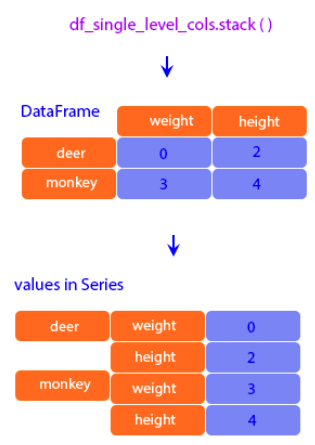

In [ ]:
pop_df = pop.unstack()   # the years become columns
pop_df

,2000,2010
California,33871648,37253956
New York,18976457,19378102
Texas,20851820,25145561


In [ ]:
pop_df.stack()           # back to the long form

California  2000    33871648
            2010    37253956
New York    2000    18976457
            2010    19378102
Texas       2000    20851820
            2010    25145561
dtype: int64

In [ ]:
# With a MultiIndex, a DataFrame can hold several measurements per (state, year)
pop_full = pd.DataFrame({'total': pop,
                         'under18': [9267089, 9284094,
                                     4687374, 4318033,
                                     5906301, 6879014]})
pop_full

total  under18
California 2000  33871648  9267089
           2010  37253956  9284094
New York   2000  18976457  4687374
           2010  19378102  4318033
Texas      2000  20851820  5906301
           2010  25145561  6879014

In [ ]:
# Fraction of people under 18, then spread years into columns
f_u18 = pop_full['under18'] / pop_full['total']
f_u18.unstack()

,2000,2010
California,0.273594,0.249211
New York,0.247010,0.222831
Texas,0.283251,0.273568


> 🔑 **Why this matters:** in two lines we computed a new measure for every (state, year) pair and reshaped it into an easy-to-read table. A MultiIndex lets one table hold data with more than two dimensions.

### **Ways to Create a MultiIndex**

In [ ]:
# 1. Pass a list of two (or more) label arrays as the index
df_multi = pd.DataFrame(rng.random((4, 2)),
                        index=[['a', 'a', 'b', 'b'], [1, 2, 1, 2]],
                        columns=['data1', 'data2'])
df_multi

data1     data2
a 1  0.967510  0.325825
  2  0.370460  0.469556
b 1  0.189471  0.129922
  2  0.475705  0.226909

In [ ]:
# 2. Pass a dictionary whose keys are tuples
pop_tuples = {('California', 2000): 33871648,
              ('California', 2010): 37253956,
              ('Texas', 2000): 20851820,
              ('Texas', 2010): 25145561,
              ('New York', 2000): 18976457,
              ('New York', 2010): 19378102}
pd.Series(pop_tuples)

California  2000    33871648
            2010    37253956
Texas       2000    20851820
            2010    25145561
New York    2000    18976457
            2010    19378102
dtype: int64

In [ ]:
# 3. from_product: EVERY combination of the lists
pd.MultiIndex.from_product([['a', 'b'], [1, 2]])

MultiIndex([('a', 1),
            ('a', 2),
            ('b', 1),
            ('b', 2)],
           )

### **Naming the Levels**

In [ ]:
pop.index.names = ['state', 'year']
pop

state       year
California  2000    33871648
            2010    37253956
New York    2000    18976457
            2010    19378102
Texas       2000    20851820
            2010    25145561
dtype: int64

### **MultiIndex for Columns Too**
Mock medical data: two years × two visits (rows), three subjects × two measurements (columns). `HR` = heart rate, `Temp` = body temperature.

In [ ]:
index = pd.MultiIndex.from_product([[2013, 2014], [1, 2]],
                                   names=['year', 'visit'])
columns = pd.MultiIndex.from_product([['Bob', 'Guido', 'Sue'], ['HR', 'Temp']],
                                     names=['subject', 'type'])

# Mock data: 4 rows x 6 columns, rounded to 1 decimal place
data = np.round(rng.standard_normal((4, 6)), 1)
data[:, ::2] = data[:, ::2] * 10 + 70   # even columns (HR): around 70 beats/min
data[:, 1::2] += 37                     # odd columns (Temp): around 37 °C

health_data = pd.DataFrame(data, index=index, columns=columns)
health_data

subject      Bob       Guido         Sue      
type          HR  Temp    HR  Temp    HR  Temp
year visit                                    
2013 1      77.0  37.7  75.0  36.3  72.0  37.1
     2      72.0  37.9  72.0  37.7  71.0  37.3
2014 1      76.0  35.5  67.0  36.5  64.0  36.7
     2      85.0  36.1  80.0  35.3  67.0  37.2

In [ ]:
# All of Sue's measurements
health_data['Sue']

type          HR  Temp
year visit            
2013 1      72.0  37.1
     2      71.0  37.3
2014 1      64.0  36.7
     2      67.0  37.2

### **Indexing and Slicing a MultiIndex Series**

In [ ]:
pop['California', 2000]        # one value: give BOTH levels

np.int64(33871648)

In [ ]:
pop['California']              # partial: give only the first level

,0
year,
2000,33871648
2010,37253956


> ⚠️ **Slicing a MultiIndex needs a sorted index.** This works because the states happen to be in alphabetical order. If your index is not sorted, run `pop = pop.sort_index()` first.

In [ ]:
print(pop.index.is_monotonic_increasing)   # True → sorted, safe to slice
pop.loc['California':'New York']

True


state       year
California  2000    33871648
            2010    37253956
New York    2000    18976457
            2010    19378102
dtype: int64

In [ ]:
pop[:, 2000]                   # every state, year 2000

,0
state,
California,33871648
New York,18976457
Texas,20851820


In [ ]:
pop[pop > 22000000]            # Boolean mask

state       year
California  2000    33871648
            2010    37253956
Texas       2010    25145561
dtype: int64

In [ ]:
pop[['California', 'Texas']]   # fancy indexing with a list

state       year
California  2000    33871648
            2010    37253956
Texas       2000    20851820
            2010    25145561
dtype: int64

### **Indexing a MultiIndexed DataFrame**

In [ ]:
health_data['Guido', 'HR']           # Guido's heart rate

year  visit
2013  1        75.0
      2        72.0
2014  1        67.0
      2        80.0
Name: (Guido, HR), dtype: float64

In [ ]:
health_data.iloc[:2, :2]             # by position

subject      Bob      
type          HR  Temp
year visit            
2013 1      77.0  37.7
     2      72.0  37.9

In [ ]:
health_data.loc[:, ('Bob', 'HR')]    # by label: pass a tuple (subject, type)

year  visit
2013  1        77.0
      2        72.0
2014  1        76.0
      2        85.0
Name: (Bob, HR), dtype: float64

In [ ]:
# pd.IndexSlice lets us use ':' inside the levels
idx = pd.IndexSlice
health_data.loc[idx[:, 1], idx[:, 'HR']]

,subject,Bob,Guido,Sue
,type,HR,HR,HR
year,visit,,,
2013,1,77.0,75.0,72.0
2014,1,76.0,67.0,64.0


> 💡 **In plain words:** `idx[:, 1]` = *any year, visit 1*. `idx[:, 'HR']` = *any subject, heart rate only*.

### **Stacking and Unstacking by Level**
Using the level **name** reads better than a number.

In [ ]:
pop.unstack('state')    # same as level=0: states become columns

state,California,New York,Texas
year,,,
2000,33871648,18976457,20851820
2010,37253956,19378102,25145561


In [ ]:
pop.unstack('year')     # same as level=1: years become columns

year,2000,2010
state,,
California,33871648,37253956
New York,18976457,19378102
Texas,20851820,25145561


In [ ]:
pop.unstack().stack()   # unstack then stack → back where we started

state       year
California  2000    33871648
            2010    37253956
New York    2000    18976457
            2010    19378102
Texas       2000    20851820
            2010    25145561
dtype: int64

### **Setting and Resetting the Index**
- `reset_index()` turns index levels into **ordinary columns** (a "flat" table, like a CSV file).
- `set_index()` does the opposite.

In [ ]:
pop_flat = pop.reset_index(name='population')
pop_flat

,state,year,population
0,California,2000,33871648
1,California,2010,37253956
2,New York,2000,18976457
3,New York,2010,19378102
4,Texas,2000,20851820
5,Texas,2010,25145561


In [ ]:
pop_flat.set_index(['state', 'year'])

population
state      year            
California 2000    33871648
           2010    37253956
New York   2000    18976457
           2010    19378102
Texas      2000    20851820
           2010    25145561

### **Aggregating with `groupby()`**
**Aggregation** combines many values into **one summary value**, e.g. `mean()`, `sum()`, `max()`.

> 💡 **In plain words:** `groupby` = **split** the rows into piles → **summarise** each pile → **combine** the answers into a new table.

In [ ]:
# Average of the two visits in each year
data_mean = health_data.groupby('year').mean()
data_mean

subject   Bob       Guido         Sue       
type       HR  Temp    HR  Temp    HR   Temp
year                                        
2013     74.5  37.8  73.5  37.0  71.5  37.20
2014     80.5  35.8  73.5  35.9  65.5  36.95

In [ ]:
# Transpose, then average across subjects for each measurement type
data_mean.T.groupby('type').mean()

year,2013,2014
type,,
HR,73.166667,73.166667
Temp,37.333333,36.216667


---
## **Part 8: Mini Case Study: Putting It All Together**

We now use everything on a **real dataset**: measurements of 344 penguins from three islands in Antarctica (*Palmer Penguins*, collected by Dr Kristen Gorman, Palmer Station LTER).

Workflow: **load → inspect → clean → new column → filter → sort → summarise**

> 📝 This cell needs an internet connection. To practise on Malaysian data, replace the URL with a CSV link from the national open data portal (https://data.gov.my) or OpenDOSM.

In [ ]:
url = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/penguins.csv"
penguins = pd.read_csv(url)
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE


### **1. Inspect**

In [ ]:
# Size, column names, data types and non-missing counts
penguins.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 7 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    object 
 1   island             344 non-null    object 
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    object 
dtypes: float64(4), object(3)
memory usage: 18.9+ KB


In [ ]:
# Quick statistics for the numeric columns
penguins.describe().round(1)

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
count,342.0,342.0,342.0,342.0
mean,43.9,17.2,200.9,4201.8
std,5.5,2.0,14.1,802.0
min,32.1,13.1,172.0,2700.0
25%,39.2,15.6,190.0,3550.0
50%,44.4,17.3,197.0,4050.0
75%,48.5,18.7,213.0,4750.0
max,59.6,21.5,231.0,6300.0


### **2. Clean: Missing Values**

In [ ]:
penguins.isna().sum()

,0
species,0
island,0
bill_length_mm,2
bill_depth_mm,2
flipper_length_mm,2
body_mass_g,2
sex,11


In [ ]:
# Rows with no body mass have no measurements at all → drop them
penguins = penguins.dropna(subset=['body_mass_g'])

# Missing sex → label it 'Unknown' rather than lose the row
penguins['sex'] = penguins['sex'].fillna('Unknown')

penguins.isna().sum()

,0
species,0
island,0
bill_length_mm,0
bill_depth_mm,0
flipper_length_mm,0
body_mass_g,0
sex,0


### **3. Create a New Column**

In [ ]:
penguins['body_mass_kg'] = penguins['body_mass_g'] / 1000
penguins.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,body_mass_kg
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,MALE,3.75
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,FEMALE,3.80
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,FEMALE,3.25
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,FEMALE,3.45
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,MALE,3.65


### **4. Filter**

In [ ]:
# Gentoo penguins heavier than 5.5 kg (Boolean mask with &)
heavy_gentoo = penguins.loc[(penguins['species'] == 'Gentoo') &
                            (penguins['body_mass_kg'] > 5.5)]
heavy_gentoo.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,body_mass_kg
221,Gentoo,Biscoe,50.0,16.3,230.0,5700.0,MALE,5.70
223,Gentoo,Biscoe,50.0,15.2,218.0,5700.0,MALE,5.70
231,Gentoo,Biscoe,49.0,16.1,216.0,5550.0,MALE,5.55
233,Gentoo,Biscoe,48.4,14.6,213.0,5850.0,MALE,5.85
235,Gentoo,Biscoe,49.3,15.7,217.0,5850.0,MALE,5.85


In [ ]:
# The same filter written with query(), which some people find easier to read
penguins.query("species == 'Gentoo' and body_mass_kg > 5.5").shape

(28, 8)

### **5. Sort**

In [ ]:
# The 5 heaviest penguins
penguins.sort_values('body_mass_kg', ascending=False).head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,body_mass_kg
237,Gentoo,Biscoe,49.2,15.2,221.0,6300.0,MALE,6.30
253,Gentoo,Biscoe,59.6,17.0,230.0,6050.0,MALE,6.05
337,Gentoo,Biscoe,48.8,16.2,222.0,6000.0,MALE,6.00
297,Gentoo,Biscoe,51.1,16.3,220.0,6000.0,MALE,6.00
299,Gentoo,Biscoe,45.2,16.4,223.0,5950.0,MALE,5.95


### **6. Summarise**

In [ ]:
# How many penguins of each species?
penguins['species'].value_counts()

,count
species,
Adelie,151
Gentoo,123
Chinstrap,68


In [ ]:
# Average mass and count per species, with readable column names
penguins.groupby('species').agg(
    mean_mass_kg=('body_mass_kg', 'mean'),
    n_penguins=('body_mass_kg', 'size')
).round(2)

,mean_mass_kg,n_penguins
species,,
Adelie,3.70,151
Chinstrap,3.73,68
Gentoo,5.08,123


In [ ]:
# Group by TWO columns → a MultiIndex → unstack into a readable table
penguins.groupby(['species', 'sex'])['body_mass_kg'].mean().unstack().round(2)

sex,FEMALE,MALE,Unknown
species,,,
Adelie,3.37,4.04,3.54
Chinstrap,3.53,3.94,NaN
Gentoo,4.68,5.48,4.59


> 🔑 The last cell uses ideas from Parts 6–7: grouping by two columns creates a **MultiIndex**, and `unstack()` turns it into a table. The `NaN` cells mean that combination does not exist in the data (no `Unknown`-sex penguins of that species).

---
## **Recap: Cheat Sheet**

| Task | Code |
|---|---|
| Make a Series / DataFrame | `pd.Series(dict)`, `pd.DataFrame({'col': series})` |
| One column as Series / as DataFrame | `df['col']` / `df[['col']]` |
| Select by **label** (end included) | `df.loc['r1':'r3', 'c1':'c2']` |
| Select by **position** (end excluded) | `df.iloc[0:3, 0:2]` |
| Filter rows | `df[(df['x'] > 1) & (df['y'] < 5)]` |
| New column | `df['z'] = df['x'] / df['y']` |
| Edit one value | `df.loc['row', 'col'] = value` |
| Count missing | `df.isna().sum()` |
| Drop missing | `df.dropna(axis=0, how='any', thresh=None)` |
| Fill missing | `df.fillna(0)`, `df.fillna(df.mean())`, `df.ffill()`, `df.bfill()` |
| Sort | `df.sort_values('col', ascending=False)` |
| Count categories | `df['col'].value_counts()` |
| Group and summarise | `df.groupby('col').agg(new=('x', 'mean'))` |
| Long → wide / wide → long | `s.unstack()` / `df.stack()` |
| Index ↔ columns | `df.reset_index()` / `df.set_index(['a', 'b'])` |

## **Practice Exercises**
Use the cleaned `penguins` DataFrame from Part 8.

1. Select the `species` and `flipper_length_mm` of the **first 5 rows** using `iloc`, then again using `loc`.
2. How many penguins live on **Biscoe** island **and** have a flipper length of **at least 210 mm**?
3. Create a column `bill_ratio` = `bill_length_mm / bill_depth_mm`. Which species has the highest average `bill_ratio`?
4. Use `groupby(['island', 'species'])` with `.size()`, then `unstack()`. Which species is found on all three islands?
5. In the **original** (uncleaned) data, fill missing `body_mass_g` with the **median** instead of dropping those rows. Why might the median be a safer choice than the mean?

### **Good luck, and see you soon!** 😀